In [1]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import pandas as pd
import matplotlib.pyplot as plt
import sys
import os
import time as tm
from torch.func import jacrev, vmap
from tqdm import tqdm
sys.path.insert(0, '../PopsCtrl/')
import function as my

# Set this to the number of physical cores you will use
num_threads = 10
tc.set_num_threads(num_threads)
tc.set_num_interop_threads(num_threads)
print(f"Threads set to: {tc.get_num_threads()}")

Threads set to: 10


In [39]:
tfinal      = 1.0
N           = 501
Nedo=12
Nfield=1

In [44]:
neuronio = [128,128]
X_vector   = my.Rede(
    neuronio    = neuronio,
    input_      = 1,
    output_     = Nedo+Nfield,
    activation  =[tc.nn.Tanh()]*len(neuronio),
    creat_p     =True,
    N_of_paramater= 0)
opt = tc.optim.Adam(X_vector.parameters(),
        lr = 0.001)
time =  tc.linspace(
        0,
        tfinal,
        N,
        dtype   = tc.float32,
        requires_grad = True).reshape((-1, 1))
#index_data = np.random.randint(0,N,size=100)
#X_vector.parametro

In [4]:
def calculate_physics_loss(time, s0, s1, wt):
    """
    s0 : (N,6)  normalised state column 0  [I00 I10 I20 R00 R10 R20]
    s1 : (N,6)  normalised state column 1  [I01 I11 I21 R01 R11 R21]
    wt : (N,1)  control field
    """
    # On-site energies & couplings
    E  = tc.tensor([0., 10., 50.], device=time.device, dtype=s0.dtype)       # (3,)
    W  = tc.tensor([[0.,  1., 3.],                            # coupling matrix (symmetric)
                    [1.,  0., 5.],
                    [3.,  5., 0.]], device=time.device, dtype=s0.dtype)       # (3,3)

    # Hamiltonian matrix H(t) = diag(E) + wt * W          — (N,3,3)
    H = E.diag().unsqueeze(0) + wt.float().unsqueeze(-1) * W                      # (N,3,3)

    # Stack both columns: psi has shape (N, 2, 6)
    # Split into imaginary [0:3] and real [3:6] parts
    I = tc.stack([s0[:, :3], s1[:, :3]], dim=1)               # (N,2,3)
    R = tc.stack([s0[:, 3:], s1[:, 3:]], dim=1)               # (N,2,3)

    # Schrödinger eqs:  dI/dt = -H @ R ,  dR/dt = H @ I
    # H @ X  for both columns at once:  (N,1,3,3) @ (N,2,3,1) → (N,2,3,1)
    HR = tc.matmul(H.unsqueeze(1), R.unsqueeze(-1)).squeeze(-1)   # (N,2,3)
    HI = tc.matmul(H.unsqueeze(1), I.unsqueeze(-1)).squeeze(-1)   # (N,2,3)

    rhs_I = -HR          # dI/dt target   (N,2,3)
    rhs_R =  HI          # dR/dt target   (N,2,3)

    # --- autograd derivatives -------------------------------------------
    # Concatenate all 12 state components → (N,12) for a single grad call
    all_vars = tc.cat([s0, s1], dim=1)                        # (N,12)
    derivs = tc.autograd.grad(all_vars, time,
                              grad_outputs=tc.ones_like(all_vars),
                              create_graph=True)[0]           # (N,1) or (N,12)

    # If time is (N,1), autograd returns (N,1); expand via the Jacobian trick:
    # We still need per-component derivatives, so keep the loop-free cat approach:
    vars_list = list(s0.split(1, dim=1)) + list(s1.split(1, dim=1))  # 12 × (N,1)
    derivs = tc.cat(
        [tc.autograd.grad(v, time, grad_outputs=tc.ones_like(v),
                          create_graph=True)[0] for v in vars_list],
        dim=1,
    )                                                          # (N,12)

    # Reshape derivs to match [I, R] × [col0, col1] layout
    dI = tc.stack([derivs[:, 0:3], derivs[:, 6:9]],  dim=1)   # (N,2,3)
    dR = tc.stack([derivs[:, 3:6], derivs[:, 9:12]], dim=1)    # (N,2,3)

    # Residual squared, summed over all components
    loss = ((dI - rhs_I)**2 + (dR - rhs_R)**2).mean()
    return loss

In [5]:
datfile = pd.read_csv('../PopsCtrl/Data/OptFieldKr_Had_GATE_3levs_alp2.csv')
ctrl = (datfile.iloc[::20, 1:]).to_numpy().copy()
ctrl.shape

(501, 1)

100%|████████████████████████████████████████| 500/500 [00:01<00:00, 391.03it/s]


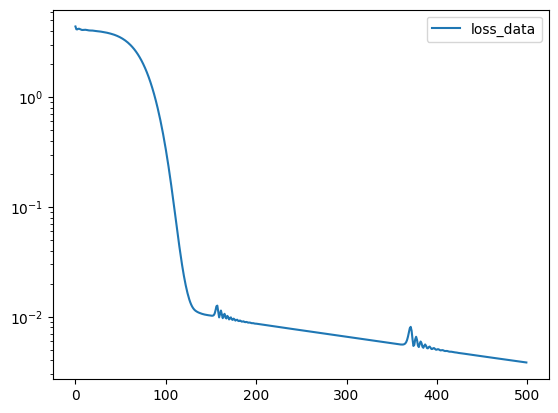

In [45]:
epocas  = 500
LOSS    = []
LOSS1   = []
LOSS2   = []
pi=tc.tensor([np.pi])
def guess_field(t):
    return pi/tfinal*tc.exp(-(t/tfinal-1/2)**2)*tc.cos(2*pi*t/tfinal)

for _ in tqdm(range(epocas)):
    ####### Forward pass #######
    y  = X_vector(time)
    LOSS_data =  y[:,0:1]**2
    LOSS_data += y[:,1:2]**2
    LOSS_data += y[:,2:3]**2
    LOSS_data += y[:,3:4]**2
    LOSS_data += y[:,4:5]**2
    LOSS_data += y[:,5:6]**2
    LOSS_data += y[:,6:7]**2
    LOSS_data += y[:,7:8]**2
    LOSS_data += y[:,8:9]**2
    LOSS_data += y[:,9:10]**2
    LOSS_data += y[:,10:11]**2
    LOSS_data += y[:,11:12]**2

    LOSS_data += (y[:,12:13]- guess_field(time))**2#tc.from_numpy(ctrl)
    LOSS_data=LOSS_data.mean()
    
    ####### Loss total #######
    loss_i =  LOSS_data.mean()

    ####### Backpropagation #######
    opt.zero_grad()
    loss_i.backward()
    opt.step()
    LOSS2.append(LOSS_data.cpu().detach().numpy())
    LOSS.append(loss_i.cpu().detach().numpy())


plt.plot(LOSS2,label="loss_data")
plt.yscale("log")
plt.legend()
plt.show()


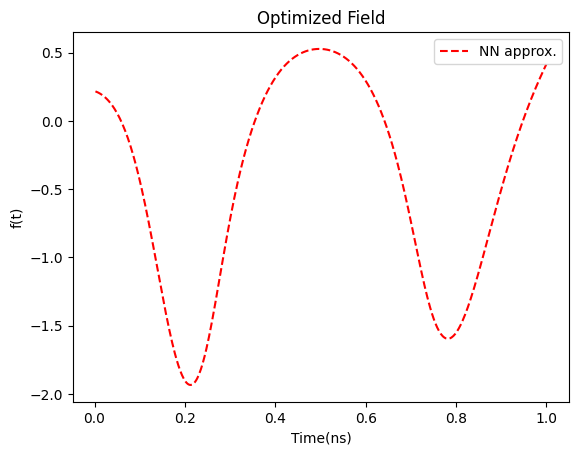

In [42]:
t_points =  np.linspace(tfinal/N,tfinal, N)
X_  = X_vector(time).detach().numpy()
w_opt=wt = tc.from_numpy(X_[:,-1])
plt.plot(t_points,w_opt,"r--", label="NN approx.")
plt.xlabel('Time(ns)')
plt.ylabel('f(t)')
#plt.plot(t_points, guess_field(time).detach().numpy(),"b-", label="Guess field")
plt.legend()
plt.title('Optimized Field')
plt.show()

100%|█████████████████████████████████████| 30000/30000 [13:51<00:00, 36.06it/s]


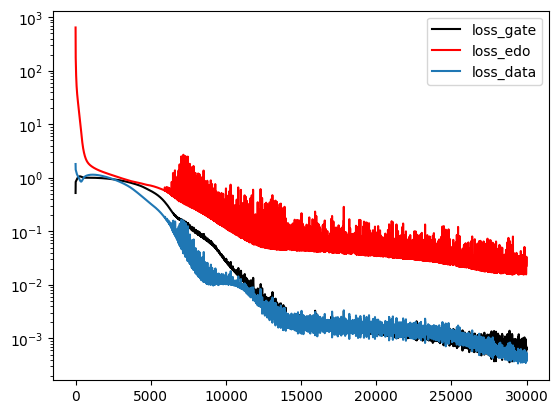

In [ ]:
epocas  = 30000
sqrt2=1.0/tc.sqrt(tc.Tensor([2.0]))
LOSS    = []
LOSS1   = []
LOSS2   = []

#The order is R00, R10, R20, R01, R11, R21, I00, I10, I20, I01, I11, I21
v0=tc.zeros(Nedo)
v0[0] = 1.;v0[4] = 1.
vt = tc.zeros(Nedo)
sqrt2=1.0/tc.sqrt(tc.Tensor([2.0]))

#X gate
#vt[1] = 1.;vt[3] = 1.

#H gate
vt[0] = sqrt2;vt[1] = sqrt2;vt[3] = sqrt2;vt[4] = -sqrt2

#S gate
#vt[0] = 1.;vt[10] = 1.

def model_fn(t):
    return X_vector(t)

for epoca in tqdm(range(epocas)):
    ####### Forward pass #######
    y  = X_vector(time)

    # Use vmap and jacrev to compute the Jacobian for every point in 'time' at once
    # This is significantly faster on both CPU and GPU
    dN_dt_full = vmap(jacrev(model_fn))(time) 
 
    # You'll need to squeeze it:
    dN_dt = dN_dt_full.squeeze()[:, :Nedo]

    # ---- split & normalise ------------------------------------------------
    state0 = y[:, :6]                  # (N,6)  I00 I10 I20 R00 R10 R20
    state1 = y[:, 6:12]               # (N,6)  I01 I11 I21 R01 R11 R21
    wt     = y[:, 12:13]              # (N,1)
    #wt = tc.from_numpy(ctrl)
    
    norma  = tc.sqrt((state0**2).sum(1, keepdim=True) + 1e-8)   # (N,1)
    norma1 = tc.sqrt((state1**2).sum(1, keepdim=True) + 1e-8)   # (N,1)
    
    s0 = state0 / norma               # (N,6) normalised
    s1 = state1 / norma1              # (N,6) normalised
    
    # keep the same 13-tuple interface for calculate_physics_loss
    regys = (*s0.split(1, dim=1), *s1.split(1, dim=1), wt)
    LOSS_edo = calculate_physics_loss(time, s0, s1, wt)
    
    # ---- gate fidelity loss -----------------------------------------------
    # Fst ordering: [R00 R10 R20 R01 R11 R21 | I00 I10 I20 I01 I11 I21] at t=-1
    Fst = tc.cat([s0[-1, 3:], s1[-1, 3:],      # real parts   (6,)
                s0[-1, :3], s1[-1, :3]])       # imag parts   (6,)
    
    tauR = (Fst[:6] * vt[:6] + Fst[6:] * vt[6:]).sum()
    tauI = (Fst[6:] * vt[:6] - Fst[:6] * vt[6:]).sum()
    
    LOSS_gate = tc.abs(1.0 - tauR / 2)# Maybe a tc.abs()
    #LOSS_gate = tc.abs(1.0 - (tauR**2 + tauI**2)/4)
    
    # ---- initial-condition loss -------------------------------------------
    psi0 = tc.cat([s0[0, 3:], s1[0, 3:],        # real parts at t=0
                s0[0, :3], s1[0, :3]])        # imag parts at t=0
    
    # I WILL TRY WITH USING THE CORRECT EXPRESSION FOR (1/2)\sum_j || |\psi_j(0)> - |\phi_j^(init)> ||^2 = 1 - \sum_j {<\psi_j(0)|\psi_j(0)>/2 - Re[<\psi_j(0)|\phi_j^(init)>]}
    #LOSS_data = ((psi0 - v0)**2).sum()           # scalar (same as .mean() on a 0-d / 1-element)
    LOSS_data = 1. + tc.dot(psi0, psi0)/2 - tc.dot(psi0, v0)
    
    # ---- leakage / state loss ---------------------------------------------
    # |ψ₂|² for both columns: I20²+R20² + I21²+R21²
    Loss_state = (s0[:, 2]**2 + s0[:, 5]**2 +
                s1[:, 2]**2 + s1[:, 5]**2).mean()
    
    ####### Loss total #######
    loss_i = LOSS_edo + LOSS_data + LOSS_gate + 0.*Loss_state
    ####### Backpropagation #######
    opt.zero_grad()
    loss_i.backward()
    opt.step()
    LOSS1.append(LOSS_edo.cpu().detach().numpy())
    LOSS2.append(LOSS_data.cpu().detach().numpy())
    LOSS.append(LOSS_gate.cpu().detach().numpy())

plt.plot(LOSS,"k-",label="loss_gate")
plt.plot(LOSS1,'r-',label="loss_edo")
plt.plot(LOSS2,label="loss_data")
plt.yscale("log")
plt.legend()
plt.show()


In [32]:
2. + tc.dot(psi0, psi0) - 2*tc.dot(psi0, v0)

tensor(0.0002, grad_fn=<SubBackward0>)

In [21]:
t_points =  np.linspace(tfinal/N,tfinal, N)
X_  = X_vector(time).detach().numpy()
#nor = np.sqrt(np.sum(X_[:,:6]**2))
#X_[:,:6] = X_[:,:6]/nor
#w_opt=X_[:,-1]
#plt.plot(t_points,w_opt,"r--")#, label="NN approx.")
#plt.xlabel('Time(ns)')
#plt.ylabel('f(t)')
#plt.plot(t_points, guess_field(time).detach().numpy(),"b-", label="Guess field")
#plt.legend()
#plt.title('Optimized Field')
#plt.show()

In [8]:
norma=np.sqrt(np.sum(X_[:,:6]**2, axis=1))
print(X_[-1,:6]/norma[-1])
norma1=np.sqrt(np.sum(X_[:,6:]**2, axis=1))
print(X_[-1,6:]/norma1[-1])


[0.6428826  0.58412004 0.1587135  0.32861382 0.3180681  0.10564797]
[ 0.50900596 -0.51145613 -0.05218522  0.21993093 -0.24249572 -0.03147182
 -0.60699093]


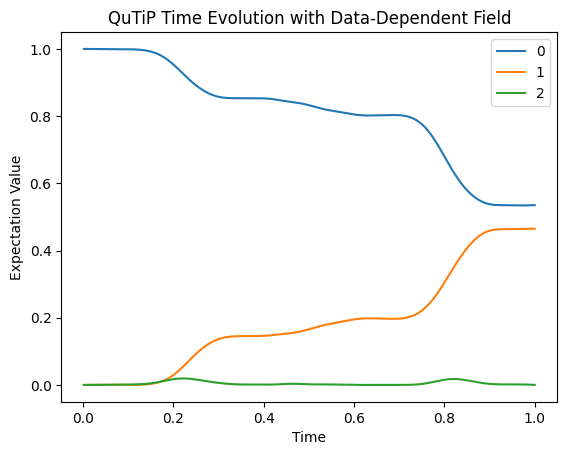

In [36]:
t_points =  np.linspace(tfinal/N,tfinal, N)
zero = qt.basis(3, 0)
one = qt.basis(3, 1)
two = qt.basis(3, 2)

sig00 = zero * zero.dag()   # |0><0|
sig11 =one *one.dag()    # |1><1|
sig22 = two * two.dag()
sig01 = zero * one.dag()   # |0><1|
sig02 = zero * two.dag() # |0><2|
sig12 = one * two.dag()   # |1><2|
sig21 = two * one.dag() # |2><1|
sig10 = one *zero.dag()   # |1><0|
sig20 = two *zero.dag() # |2><0|

E0=0;E1=10;E2=50
w01=1;w02=3;w12=5
H0 = E1*sig11+E2*sig22
H1 = w01*(sig01+sig10)+w02*(sig02+sig20)+w12*(sig12+sig21)
# The full Hamiltonian is defined as a list: 
# H = H0 + f(t) * H1, where f(t) is the field data
H = [H0, [H1, ctrl.flatten()]] # QuTiP uses cubic spline interpolation for field_data


# 3. Define the initial state and expectation value operators
psi0 = qt.basis(3, 0)# + qt.basis(3, 1)).unit() # Initial state |0>
e_ops = [sig00, sig11, sig22] # Operators for which to calculate expectation values

# 4. Simulate the time evolution
result = qt.sesolve(H, psi0, t_points, e_ops)

# 5. Plot the results
plt.figure()
plt.plot(t_points, result.expect[0], label='0')
plt.plot(t_points, result.expect[1], label='1')
plt.plot(t_points, result.expect[2], label='2')
#plt.plot(t_points,(X_[:,0]**2+X_[:,2]**2)/norma)
#plt.plot(t_points,(X_[:,1]**2+X_[:,3]**2)/norma)
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('QuTiP Time Evolution with Data-Dependent Field')
plt.show()


In [60]:
result.expect[0][-1]

np.float64(0.9962828288176895)

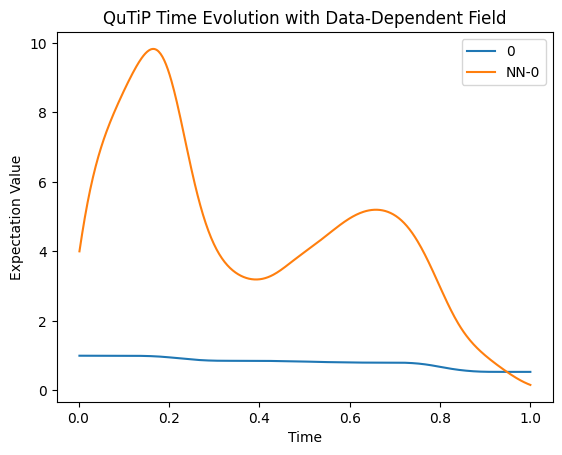

In [37]:
plt.figure()
plt.plot(t_points, result.expect[0], label='0')
plt.plot(t_points, (X_[:,3]**2+X_[:,0]**2), label='NN-0')
#plt.plot(t_points,(X_[:,0]**2+X_[:,2]**2)/norma)
#plt.plot(t_points,(X_[:,1]**2+X_[:,3]**2)/norma)
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('QuTiP Time Evolution with Data-Dependent Field')
plt.show()
